In [2]:
import pandas as pd
import numpy as np
import os

In [13]:
X_train = pd.read_csv("/home/irene/projects/hackathon-synth-data-2026/data/mortality-prediction-kaggle/X_train_2025.csv")
y_train = pd.read_csv("/home/irene/projects/hackathon-synth-data-2026/data/mortality-prediction-kaggle/y_train_2025.csv")

In [14]:
X_train.columns.to_list()

['recordid',
 'SAPS-I',
 'SOFA',
 'Age',
 'Gender',
 'Height',
 'Weight',
 'CCU',
 'CSRU',
 'SICU',
 'DiasABP_first',
 'GCS_first',
 'Glucose_first',
 'HR_first',
 'MAP_first',
 'NIDiasABP_first',
 'NIMAP_first',
 'NISysABP_first',
 'RespRate_first',
 'SaO2_first',
 'SysABP_first',
 'Temp_first',
 'DiasABP_last',
 'GCS_last',
 'Glucose_last',
 'HR_last',
 'MAP_last',
 'NIDiasABP_last',
 'NIMAP_last',
 'NISysABP_last',
 'RespRate_last',
 'SaO2_last',
 'SysABP_last',
 'Temp_last',
 'DiasABP_lowest',
 'GCS_lowest',
 'Glucose_lowest',
 'HR_lowest',
 'MAP_lowest',
 'NIDiasABP_lowest',
 'NIMAP_lowest',
 'NISysABP_lowest',
 'RespRate_lowest',
 'SaO2_lowest',
 'SysABP_lowest',
 'Temp_lowest',
 'DiasABP_highest',
 'GCS_highest',
 'Glucose_highest',
 'HR_highest',
 'MAP_highest',
 'NIDiasABP_highest',
 'NIMAP_highest',
 'NISysABP_highest',
 'RespRate_highest',
 'SaO2_highest',
 'SysABP_highest',
 'Temp_highest',
 'DiasABP_median',
 'GCS_median',
 'Glucose_median',
 'HR_median',
 'MAP_median',
 '

<Axes: >

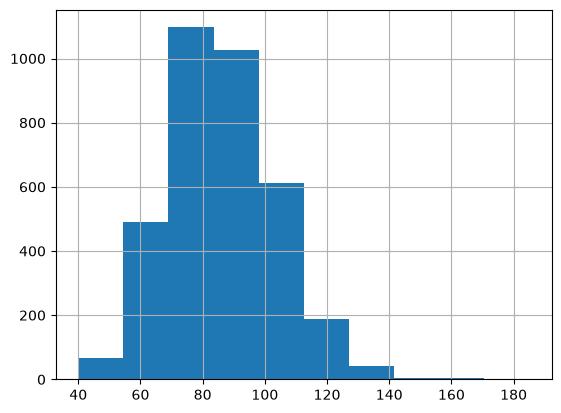

In [15]:
X_train['HR_last'].hist()

In [18]:
df = X_train.copy()
df['mortality'] = y_train
# df["mortality"] = df["mortality"].map({
#     0: "control",
#     1: "case"
# })

In [19]:
df['mortality'].value_counts()

mortality
0    3097
1     503
Name: count, dtype: int64

In [31]:
save_path = "/home/irene/projects/hackathon-synth-data-2026/data/prepped/mortality-prediction-kaggle/for_synthetic-data-generator/"
os.makedirs(save_path, exist_ok=True)
df.to_parquet(os.path.join(save_path,"mortality_full.parquet"), index=False)

In [33]:
categorical_vars= [
"Gender",
"CCU",
"CSRU",
"SICU",
"MechVentLast8Hour",
"mortality"
]

In [35]:
for var in categorical_vars: print(var, df[var].dtype)

Gender float64
CCU int64
CSRU int64
SICU int64
MechVentLast8Hour float64
mortality object


In [44]:
df[['Gender', 'MechVentLast8Hour']] = (
    df[['Gender', 'MechVentLast8Hour']]
    .astype("Int64")
    .astype("category")
)

In [45]:
for var in categorical_vars: print(var, df[var].dtype)

Gender category
CCU int64
CSRU int64
SICU int64
MechVentLast8Hour category
mortality object


In [47]:
save_path = "/home/irene/projects/hackathon-synth-data-2026/data/prepped/mortality-prediction-kaggle/for_synthetic-data-generator/"
os.makedirs(save_path, exist_ok=True)
df.to_parquet(os.path.join(save_path,"mortality_full.parquet"), index=False)

In [3]:
df_synth = pd.read_parquet('/home/irene/projects_output/hackathon/2026-11-12_GaussianCopula-kaggleDataset/synthetic_data/synthetic_data.parquet')

In [9]:
df = df_synth.copy()
df["mortality"] = df["mortality"].map({
    "control": 0,
    "case":1
}).astype('int')

In [11]:
df.to_parquet('/home/irene/projects_output/hackathon/2026-11-12_GaussianCopula-kaggleDataset/synthetic_data/synthetic_data_forSubmision.parquet')
df.to_parquet('/home/irene/projects_output/hackathon/2026-11-12_GaussianCopula-kaggleDataset/synthetic_data/synthetic_data_forSubmision.csv')

In [12]:
df['mortality'].unique()

array([1, 0])

In [20]:
real_train = pd.read_parquet('/home/irene/projects/hackathon-synth-data-2026/data/prepped/mortality-prediction-kaggle/for_synthetic-data-generator/trainTestSplit/real_train.parquet')
real_test = pd.read_parquet('/home/irene/projects/hackathon-synth-data-2026/data/prepped/mortality-prediction-kaggle/for_synthetic-data-generator/trainTestSplit/real_test.parquet')

In [24]:
train = real_train.copy()
train ["mortality"] = train ["mortality"].map({
    "control": 0,
    "case":1
}).astype('int')

test = real_test.copy()
test["mortality"] = test["mortality"].map({
    "control": 0,
    "case":1
}).astype('int')

In [30]:
train.to_parquet('/home/irene/projects/hackathon-synth-data-2026/data/prepped/mortality-prediction-kaggle/trainTestSplit/real_train.parquet')
test.to_parquet('/home/irene/projects/hackathon-synth-data-2026/data/prepped/mortality-prediction-kaggle/trainTestSplit/real_test.parquet')

In [31]:
train.to_csv('/home/irene/projects/hackathon-synth-data-2026/data/prepped/mortality-prediction-kaggle/trainTestSplit/real_train.csv')
test.to_csv('/home/irene/projects/hackathon-synth-data-2026/data/prepped/mortality-prediction-kaggle/trainTestSplit/real_test.csv')